## Pandas analysis

This exercise consists in analyzing a dataset containg timing information from a series of Time-to-Digital-Converters (TDC) implemented in a couple of FPGAs. Each measurement (i.e. each row of the input file) consists of a flag that specifies the type of message ('HEAD', which in this case is always 1), two addresses of the TDC providing the signal ('FPGA' and 'TDC_CHANNEL'), and the timing information ('ORBIT_CNT', 'BX_COUNTER', and 'TDC_MEAS'). Each TDC count corresponds to 25/30 ns, whereas a unit of BX_COUNTER corresponds to 25 ns, and the ORBIT_CNT is increased every 'x' BX_COUNTER. This allows to store the time in a similar way to hours, minutes and seconds.

In [13]:
!wget -O data_000637.txt "https://www.dropbox.com/scl/fi/pkkpoxlm7beasryexpdf8/data_000637.txt?rlkey=rkm2em1v57hewglzelmin21c9&dl=1"

zsh:1: command not found: wget


1\. Create a Pandas DataFrame reading N rows of the 'data_000637.txt' dataset. Choose N to be smaller than or equal to the maximum number of rows and larger that 10k.

2\. Find out the number of BX in a ORBIT (the value 'x').

3\. Find out how much the data taking lasted. You can either make an estimate based on the fraction of the measurements (rows) you read, or perform this check precisely by reading out the whole dataset.

4\. Create a new column with the absolute time in ns (as a combination of the other three columns with timing information).

5\. Replace the values (all 1) of the HEAD column randomly with 0 or 1.

6\. Create a new DataFrame that contains only the rows with HEAD=1.

7\. Make two occupancy plots (one for each FPGA), i.e. plot the number of counts per TDC channel

8\. Use the groupby method to find out the noisy channels, i.e. the TDC channels with most counts (say the top 3)

9\. Count the number of unique orbits. Count the number of unique orbits with at least one measurement from TDC_CHANNEL=139

In [14]:
#exercise 1

import pandas as pd
import random as rd

file_name="data_000637.txt"
data=pd.read_csv(file_name)

n_raw=data.shape[0]
N=rd.randint(10000,n_raw)

data.tail(N)

df=pd.DataFrame(data)
df

,HEAD,FPGA,TDC_CHANNEL,ORBIT_CNT,BX_COUNTER,TDC_MEAS
0,1,0,123,3869200167,2374,26
1,1,0,124,3869200167,2374,27
2,1,0,63,3869200167,2553,28
3,1,0,64,3869200167,2558,19
4,1,0,64,3869200167,2760,25
...,...,...,...,...,...,...
1310715,1,0,62,3869211171,762,14
1310716,1,1,4,3869211171,763,11
1310717,1,0,64,3869211171,764,0
1310718,1,0,139,3869211171,769,0


In [15]:
#exercise 2
data.tail(n_raw)

df=pd.DataFrame(data)
df_stats=df.describe()
print(df_stats)
x=df_stats.iloc[-1,4]
print('The number of BX in an ORBIT is', x)

            HEAD          FPGA   TDC_CHANNEL     ORBIT_CNT    BX_COUNTER  \
count  1310720.0  1.310720e+06  1.310720e+06  1.310720e+06  1.310720e+06   
mean         1.0  2.959198e-01  5.582570e+01  3.869206e+09  1.781096e+03   
std          0.0  4.564553e-01  3.901034e+01  3.183124e+03  1.027795e+03   
min          1.0  0.000000e+00  1.000000e+00  3.869200e+09  0.000000e+00   
25%          1.0  0.000000e+00  2.600000e+01  3.869203e+09  8.930000e+02   
50%          1.0  0.000000e+00  5.700000e+01  3.869207e+09  1.778000e+03   
75%          1.0  1.000000e+00  6.400000e+01  3.869209e+09  2.670000e+03   
max          1.0  1.000000e+00  1.390000e+02  3.869211e+09  3.563000e+03   

           TDC_MEAS  
count  1.310720e+06  
mean   1.332340e+01  
std    9.199886e+00  
min    0.000000e+00  
25%    5.000000e+00  
50%    1.300000e+01  
75%    2.100000e+01  
max    2.900000e+01  
The number of BX in an ORBIT is 3563.0


In [16]:
#exercise 3
final_time=(df.iloc[-1,3]*(x+1) + df.iloc[-1,4])*25 + df.iloc[-1,5]*(25/30)
initial_time=(df.iloc[1,3]*(x+1) + df.iloc[1,4])*25 + df.iloc[1,5]*(25/30)
duration= final_time-initial_time
print('The entire measurements took', duration, 'ns=',duration*10**(-9), 's')

The entire measurements took 980416092.5 ns= 0.9804160925000001 s


In [17]:
#exercise 4 
import numpy as np
df['E'] = (df['ORBIT_CNT']*(x+1) + df['BX_COUNTER'])*25 + df['TDC_MEAS']*(25/30)
print(df)


         HEAD  FPGA  TDC_CHANNEL   ORBIT_CNT  BX_COUNTER  TDC_MEAS  \
0           1     0          123  3869200167        2374        26   
1           1     0          124  3869200167        2374        27   
2           1     0           63  3869200167        2553        28   
3           1     0           64  3869200167        2558        19   
4           1     0           64  3869200167        2760        25   
...       ...   ...          ...         ...         ...       ...   
1310715     1     0           62  3869211171         762        14   
1310716     1     1            4  3869211171         763        11   
1310717     1     0           64  3869211171         764         0   
1310718     1     0          139  3869211171         769         0   
1310719     1     0           61  3869211171         762        18   

                    E  
0        3.447457e+14  
1        3.447457e+14  
2        3.447457e+14  
3        3.447457e+14  
4        3.447457e+14  
...            

In [24]:
#exercise5. Replace the values (all 1) of the HEAD column randomly with 0 or 1.
df.loc[:, "HEAD"] = [rd.randint(0, 1) for i in range(len(df))]
print(df)

         HEAD  FPGA  TDC_CHANNEL   ORBIT_CNT  BX_COUNTER  TDC_MEAS  \
0           0     0          123  3869200167        2374        26   
1           0     0          124  3869200167        2374        27   
2           1     0           63  3869200167        2553        28   
3           1     0           64  3869200167        2558        19   
4           1     0           64  3869200167        2760        25   
...       ...   ...          ...         ...         ...       ...   
1310715     1     0           62  3869211171         762        14   
1310716     0     1            4  3869211171         763        11   
1310717     0     0           64  3869211171         764         0   
1310718     0     0          139  3869211171         769         0   
1310719     1     0           61  3869211171         762        18   

                    E  
0        3.447457e+14  
1        3.447457e+14  
2        3.447457e+14  
3        3.447457e+14  
4        3.447457e+14  
...            

In [32]:
#exercise6. Create a new DataFrame that contains only the rows with HEAD=1.

new_df = df[df["HEAD"]==1]
print(new_df)

         HEAD  FPGA  TDC_CHANNEL   ORBIT_CNT  BX_COUNTER  TDC_MEAS  \
2           1     0           63  3869200167        2553        28   
3           1     0           64  3869200167        2558        19   
4           1     0           64  3869200167        2760        25   
6           1     0           61  3869200167        2772        14   
8           1     0           62  3869200167        2774        21   
...       ...   ...          ...         ...         ...       ...   
1310708     1     0          124  3869211171         199         9   
1310710     1     1           36  3869211171         427        13   
1310713     1     0           64  3869211171         758        18   
1310715     1     0           62  3869211171         762        14   
1310719     1     0           61  3869211171         762        18   

                    E  
2        3.447457e+14  
3        3.447457e+14  
4        3.447457e+14  
6        3.447457e+14  
8        3.447457e+14  
...            

Text(0.5, 1.0, 'occupacy plot for FPGA=0')

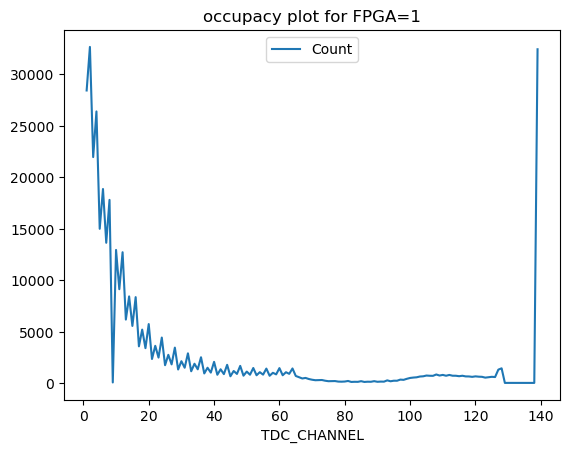

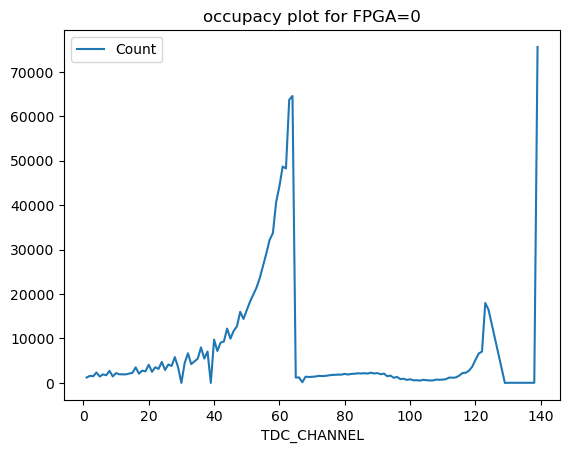

In [63]:
#exercise7. Make two occupancy plots (one for each FPGA), i.e. plot the number of counts per TDC channel

#occupacy plot for FPGA=1
FPGA_df=df[df["FPGA"]==1]

FPGA_df=FPGA_df.sort_values(by="TDC_CHANNEL")
def channel_aggregation(group):
    return pd.Series({'Count': group['TDC_CHANNEL'].count()})
result = FPGA_df.groupby('TDC_CHANNEL').apply(channel_aggregation)
#print(result)
#print(result["Count"])
#print(result.index)

import matplotlib.pyplot as plt
result.plot(); plt.legend(); plt.title('occupacy plot for FPGA=1')

####

#occupacy plot for FPGA=0

nFPGA_df=df[df["FPGA"]==0]

nFPGA_df=nFPGA_df.sort_values(by="TDC_CHANNEL")
result = nFPGA_df.groupby('TDC_CHANNEL').apply(channel_aggregation)

import matplotlib.pyplot as plt
result.plot(); plt.legend(); plt.title('occupacy plot for FPGA=0')
#print(not_FPGA_df)


In [71]:
#exercise 8:Use the groupby method to find out the noisy channels, i.e. the TDC channels with most counts (say the top 3)
result=result.sort_values(by='Count', ascending=True)
print(result)
noisy_channels=result.tail(3)
print(noisy_channels)

             Count
TDC_CHANNEL       
39               1
129              2
30               4
137             32
130             33
...            ...
62           48275
61           48699
63           63724
64           64581
139          75617

[124 rows x 1 columns]
             Count
TDC_CHANNEL       
63           63724
64           64581
139          75617


         HEAD  FPGA  TDC_CHANNEL   ORBIT_CNT  BX_COUNTER  TDC_MEAS  \
0           0     0          123  3869200167        2374        26   
1           0     0          124  3869200167        2374        27   
2           1     0           63  3869200167        2553        28   
3           1     0           64  3869200167        2558        19   
4           1     0           64  3869200167        2760        25   
...       ...   ...          ...         ...         ...       ...   
1310715     1     0           62  3869211171         762        14   
1310716     0     1            4  3869211171         763        11   
1310717     0     0           64  3869211171         764         0   
1310718     0     0          139  3869211171         769         0   
1310719     1     0           61  3869211171         762        18   

                    E  
0        3.447457e+14  
1        3.447457e+14  
2        3.447457e+14  
3        3.447457e+14  
4        3.447457e+14  
...            

In [81]:
#exercise9. Count the number of unique orbits. Count the number of unique orbits with at least one measurement from TDC_CHANNEL=139

def orbit_aggregation(group):
    return pd.Series({'Count': group['ORBIT_CNT'].count()})
result = df.groupby('ORBIT_CNT').apply(orbit_aggregation)
print(result)
print('The number of unique orbits is:', len(result))

new_df=df[df['TDC_CHANNEL']==139]

new_result = new_df.groupby('ORBIT_CNT').apply(orbit_aggregation)
print(new_result)
print('The number of unique orbits  with at least one measurement from TDC_CHANNEL=139 is:', len(new_result))


            Count
ORBIT_CNT        
3869200167     43
3869200168     85
3869200169    127
3869200170     98
3869200171    109
...           ...
3869211167    208
3869211168    109
3869211169    191
3869211170    137
3869211171     22

[11001 rows x 1 columns]
The number of unique orbits is: 11001
            Count
ORBIT_CNT        
3869200167      4
3869200168      8
3869200169     11
3869200170      9
3869200171      9
...           ...
3869211167     19
3869211168      8
3869211169     13
3869211170     12
3869211171      2

[10976 rows x 1 columns]
The number of unique orbits  with at least one measurement from TDC_CHANNEL=139 is: 10976
